# Airline Passenger Satisfaction – Classification & Driver Analysis

This notebook predicts whether an airline passenger is **satisfied** or **neutral/dissatisfied** from their demographics, trip details and in-flight service ratings — and, more importantly, explains **what drives satisfaction**.

**Workflow overview**
1. Load and inspect the raw dataset
2. Explore the data on its *original* categories (EDA) – segments, service ratings, delays, missingness
3. Split into train/test **before** any fitting, so no information leaks from the test set
4. Build a leak-free preprocessing pipeline (imputation, missing-value flags, log transform, scaling, encoding)
5. Handle the mild class imbalance with stratification and class weights
6. Compare Logistic Regression, XGBoost and Random Forest with 5-fold stratified cross-validation
7. Tune each model with the same CV scheme and evaluate once on the untouched test set
8. Interpret the models – coefficients, permutation importance, SHAP, partial dependence and segment analysis
9. Refit the best model on all labelled data and write `submission.csv` for the Kaggle competition ([Playground Series S6E10](https://www.kaggle.com/competitions/playground-series-s6e10), scored on ROC-AUC)

## Dataset Preparation

We start by importing the required libraries, loading the CSV file and taking a first look at its structure, summary statistics, data types and missing values.

In [1]:
# ---------------------------------------------------------------
# Library imports
# ---------------------------------------------------------------
# Data handling
import os
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import warnings

# Modelling, preprocessing and evaluation
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report,
                             confusion_matrix, RocCurveDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import xgboost as xgb

# Silence noisy warnings that do not affect the results
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

# ---------------------------------------------------------------
# Load the data
#  - On Kaggle (Playground S6E10): train.csv, test.csv and sample_submission.csv
#    are read from /kaggle/input and a submission file is written at the end
#  - Locally / on Colab: airline_dataset.csv is used and no submission is written
# ---------------------------------------------------------------
import glob

INPUT_DIR = '/kaggle/input'

def find_input_file(file_name):
    matches = sorted(glob.glob(f'{INPUT_DIR}/**/{file_name}', recursive=True))
    return matches[0] if matches else None

train_path = find_input_file('train.csv')
test_path = find_input_file('test.csv')
sample_sub_path = find_input_file('sample_submission.csv')
COMPETITION_MODE = all([train_path, test_path, sample_sub_path])

if COMPETITION_MODE:
    airline_df = pd.read_csv(train_path)
    competition_test_df = pd.read_csv(test_path)
    sample_submission = pd.read_csv(sample_sub_path)
    print('Competition mode | train:', train_path, '| test:', test_path)
else:
    local_paths = (['airline_dataset.csv', '/content/airline_dataset.csv']
                   + sorted(glob.glob(f'{INPUT_DIR}/**/airline_dataset.csv', recursive=True)))
    existing_paths = [path for path in local_paths if os.path.exists(path)]
    if not existing_paths:
        raise FileNotFoundError('No data found. On Kaggle, attach the competition data via "Add Input". '
                                f'CSV files under {INPUT_DIR}: {glob.glob(f"{INPUT_DIR}/**/*.csv", recursive=True)}')
    airline_df = pd.read_csv(existing_paths[0])
    print('Local mode | data:', existing_paths[0], '(no submission file will be written)')

# Identify the id and target columns (taken from sample_submission in competition mode)
ID_COL = sample_submission.columns[0] if COMPETITION_MODE else 'id'
TARGET_COL = sample_submission.columns[1] if COMPETITION_MODE else 'satisfaction'
ID_COLS = [column for column in ['Unnamed: 0', ID_COL] if column in airline_df.columns]

def to_binary(target):
    # Convert the target to 0/1 – works for text labels ('satisfied' / 'neutral or dissatisfied') and 0/1 labels
    if target.dtype == object:
        return (target.str.strip().str.lower() == 'satisfied').astype(int)
    return target.astype(int)

print('ID column:', ID_COL, '| Target column:', TARGET_COL, '| Target values:', airline_df[TARGET_COL].unique()[:5])

# Overview of columns, non-null counts and data types
airline_df.info()

Local mode | data: airline_dataset.csv (no submission file will be written)
ID column: id | Target column: satisfaction | Target values: ['neutral or dissatisfied' 'satisfied']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                94553 non-null   float64
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    93514 non-null   float64
 8   Inflight wifi service              103904 non-null  int64

In [2]:
# Preview the first five rows to get a feel for the data
airline_df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13.0,Personal Travel,Eco Plus,460.0,3,4,...,5.0,4,3,4.0,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25.0,Business travel,Business,235.0,3,2,...,1.0,1,5,3.0,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26.0,Business travel,Business,1142.0,2,2,...,5.0,4,3,4.0,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25.0,Business travel,Business,562.0,2,5,...,2.0,2,5,3.0,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61.0,Business travel,Business,214.0,3,3,...,3.0,3,4,4.0,3,3,3,0,0.0,satisfied


In [3]:
# Summary statistics (count, mean, spread, quartiles) for every numeric column
airline_df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,94553.000000,93514.000000,103904.000000,103904.000000,103904.000000,96631.000000,103904.000000,103904.000000,103904.000000,83124.000000,103904.000000,103904.000000,95073.000000,103904.000000,103904.000000,103904.000000,103904.000000,103594.000000
mean,51951.500000,64924.210502,39.359957,1188.977661,2.729683,3.060296,2.756901,2.976208,3.202129,3.250375,3.439396,3.354675,3.382363,3.351055,3.631599,3.304290,3.640428,3.286351,14.815618,15.178678
std,29994.645522,37463.812252,15.127041,996.971727,1.327829,1.525075,1.398929,1.276947,1.329533,1.349509,1.319088,1.331660,1.288354,1.315605,1.180791,1.265396,1.175663,1.312273,38.230901,38.698682
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25975.750000,32533.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,51951.500000,64856.500000,40.000000,842.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,77927.250000,97368.250000,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [4]:
# Number and percentage of missing values in each column
missing_summary = pd.DataFrame({
    'missing': airline_df.isnull().sum(),
    'percent': (airline_df.isnull().mean() * 100).round(2)
})
missing_summary[missing_summary['missing'] > 0]

,missing,percent
Age,9351,9.0
Flight Distance,10390,10.0
Gate location,7273,7.0
Inflight entertainment,20780,20.0
Baggage handling,8831,8.5
Arrival Delay in Minutes,310,0.3


# Exploratory Data Analysis (EDA)

EDA is done on the **raw categories** (before one-hot encoding) so the plots read in plain language, e.g. *"Business class"* rather than `Class_Eco = False`. For each view we look at the **satisfaction rate** – the share of passengers who are satisfied – because that is directly what we want to explain.

To keep the plots readable, the target is turned into a 0/1 column (`satisfied`) on a copy of the data. No values are imputed or transformed here.

satisfaction label
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64
satisfaction label
neutral or dissatisfied    56.7 %
satisfied                  43.3 %
Name: count, dtype: object


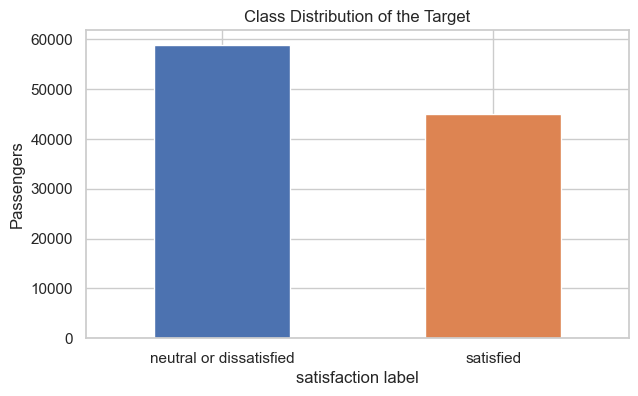

In [5]:
# Working copy for EDA with a binary target
eda_df = airline_df.drop(columns=ID_COLS).copy()
eda_df['satisfied'] = to_binary(eda_df[TARGET_COL])
eda_df['satisfaction label'] = eda_df['satisfied'].map({0: 'neutral or dissatisfied', 1: 'satisfied'})

# Column groups used throughout the notebook
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
rating_cols = ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
               'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
               'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling',
               'Checkin service', 'Inflight service', 'Cleanliness']
continuous_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

# Keep only the columns that exist in this version of the data
categorical_cols = [c for c in categorical_cols if c in eda_df.columns]
rating_cols = [c for c in rating_cols if c in eda_df.columns]
continuous_cols = [c for c in continuous_cols if c in eda_df.columns]

# ---------------------------------------------------------------
# 1. Distribution of the target classes
# ---------------------------------------------------------------
target_class_counts = eda_df['satisfaction label'].value_counts()
print(target_class_counts)
print((target_class_counts / len(eda_df) * 100).round(1).astype(str) + ' %')

plt.figure(figsize=(7, 4))
target_class_counts.plot(kind='bar', color=['#4c72b0', '#dd8452'])
plt.title('Class Distribution of the Target')
plt.ylabel('Passengers')
plt.xticks(rotation=0)
plt.show()

The split is roughly **57 % / 43 %** – only a *mild* imbalance. Heavy resampling such as SMOTE is not required; stratified splitting plus class weights (used later) is enough and avoids adding synthetic rows.

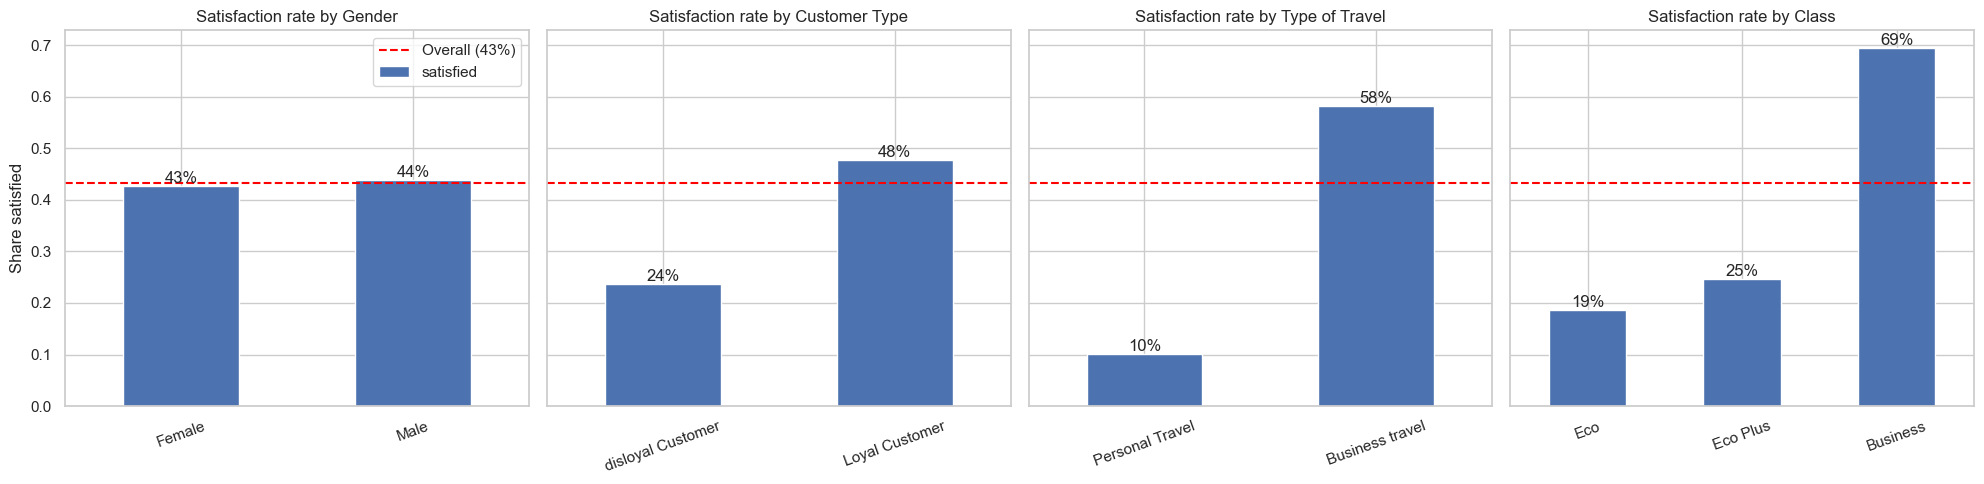

In [6]:
# ---------------------------------------------------------------
# 2. Satisfaction rate by each categorical feature
# ---------------------------------------------------------------
overall_rate = eda_df['satisfied'].mean()
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, column in zip(axes, categorical_cols):
    rates = eda_df.groupby(column)['satisfied'].mean().sort_values()
    rates.plot(kind='bar', ax=ax, color='#4c72b0')
    ax.axhline(overall_rate, color='red', linestyle='--', label=f'Overall ({overall_rate:.0%})')
    ax.set_title(f'Satisfaction rate by {column}')
    ax.set_ylabel('Share satisfied')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
    for patch, value in zip(ax.patches, rates):
        ax.annotate(f'{value:.0%}', (patch.get_x() + patch.get_width() / 2, value), ha='center', va='bottom')
axes[0].legend()
plt.tight_layout()
plt.show()

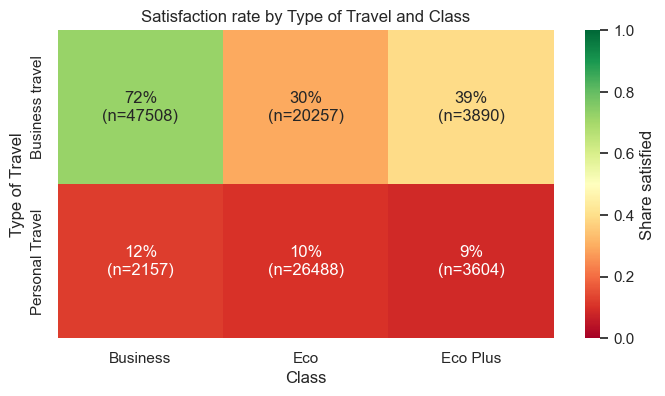

In [7]:
# ---------------------------------------------------------------
# 3. Interaction: Type of Travel x Class (and passenger counts)
# ---------------------------------------------------------------
segment_rates = eda_df.pivot_table(index='Type of Travel', columns='Class', values='satisfied', aggfunc='mean')
segment_counts = eda_df.pivot_table(index='Type of Travel', columns='Class', values='satisfied', aggfunc='size')
annotations = segment_rates.map(lambda v: f'{v:.0%}') + '\n(n=' + segment_counts.astype(str) + ')'

plt.figure(figsize=(8, 4))
sns.heatmap(segment_rates, annot=annotations, fmt='', cmap='RdYlGn', vmin=0, vmax=1, cbar_kws={'label': 'Share satisfied'})
plt.title('Satisfaction rate by Type of Travel and Class')
plt.show()

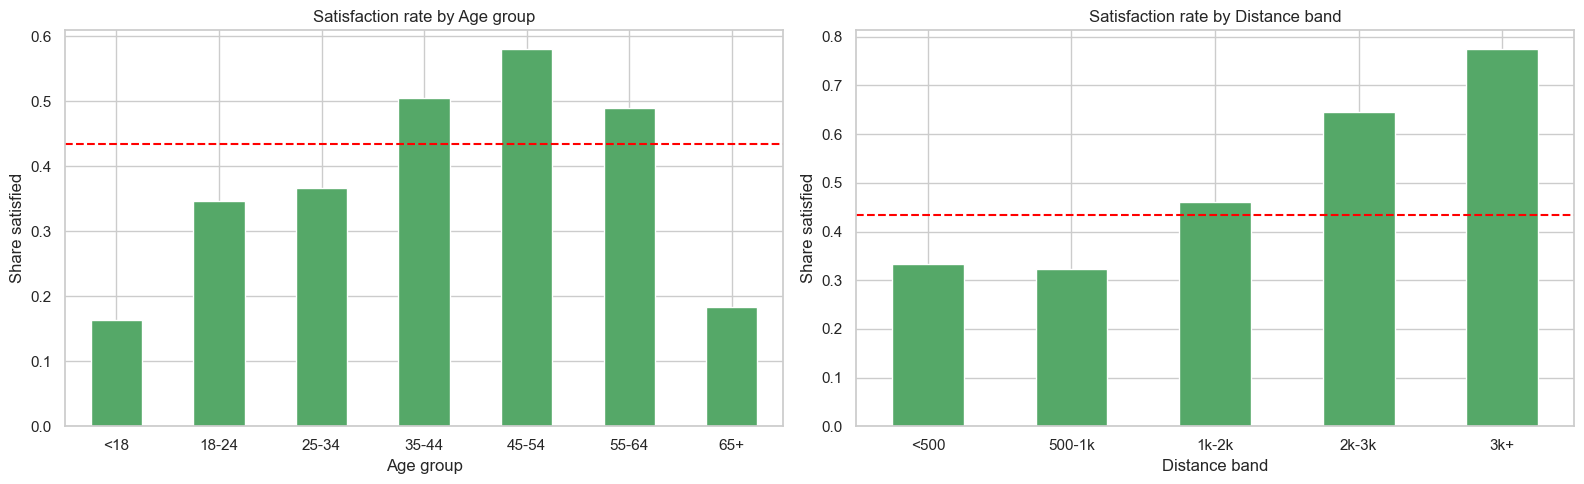

In [8]:
# ---------------------------------------------------------------
# 4. Satisfaction rate by age group and by flight-distance band
# ---------------------------------------------------------------
eda_df['Age group'] = pd.cut(eda_df['Age'], bins=[0, 17, 24, 34, 44, 54, 64, 100],
                             labels=['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+'])
eda_df['Distance band'] = pd.cut(eda_df['Flight Distance'], bins=[0, 500, 1000, 2000, 3000, np.inf],
                                 labels=['<500', '500-1k', '1k-2k', '2k-3k', '3k+'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, column in zip(axes, ['Age group', 'Distance band']):
    eda_df.groupby(column, observed=True)['satisfied'].mean().plot(kind='bar', ax=ax, color='#55a868')
    ax.axhline(overall_rate, color='red', linestyle='--')
    ax.set_title(f'Satisfaction rate by {column}')
    ax.set_ylabel('Share satisfied')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Service ratings vs satisfaction

The 14 service ratings (0–5) are the core of this dataset. A rating of **0** means the passenger did not rate / the service was not applicable. Below, each panel shows the satisfaction rate at every rating level – a steep line means that service strongly separates satisfied from dissatisfied passengers.

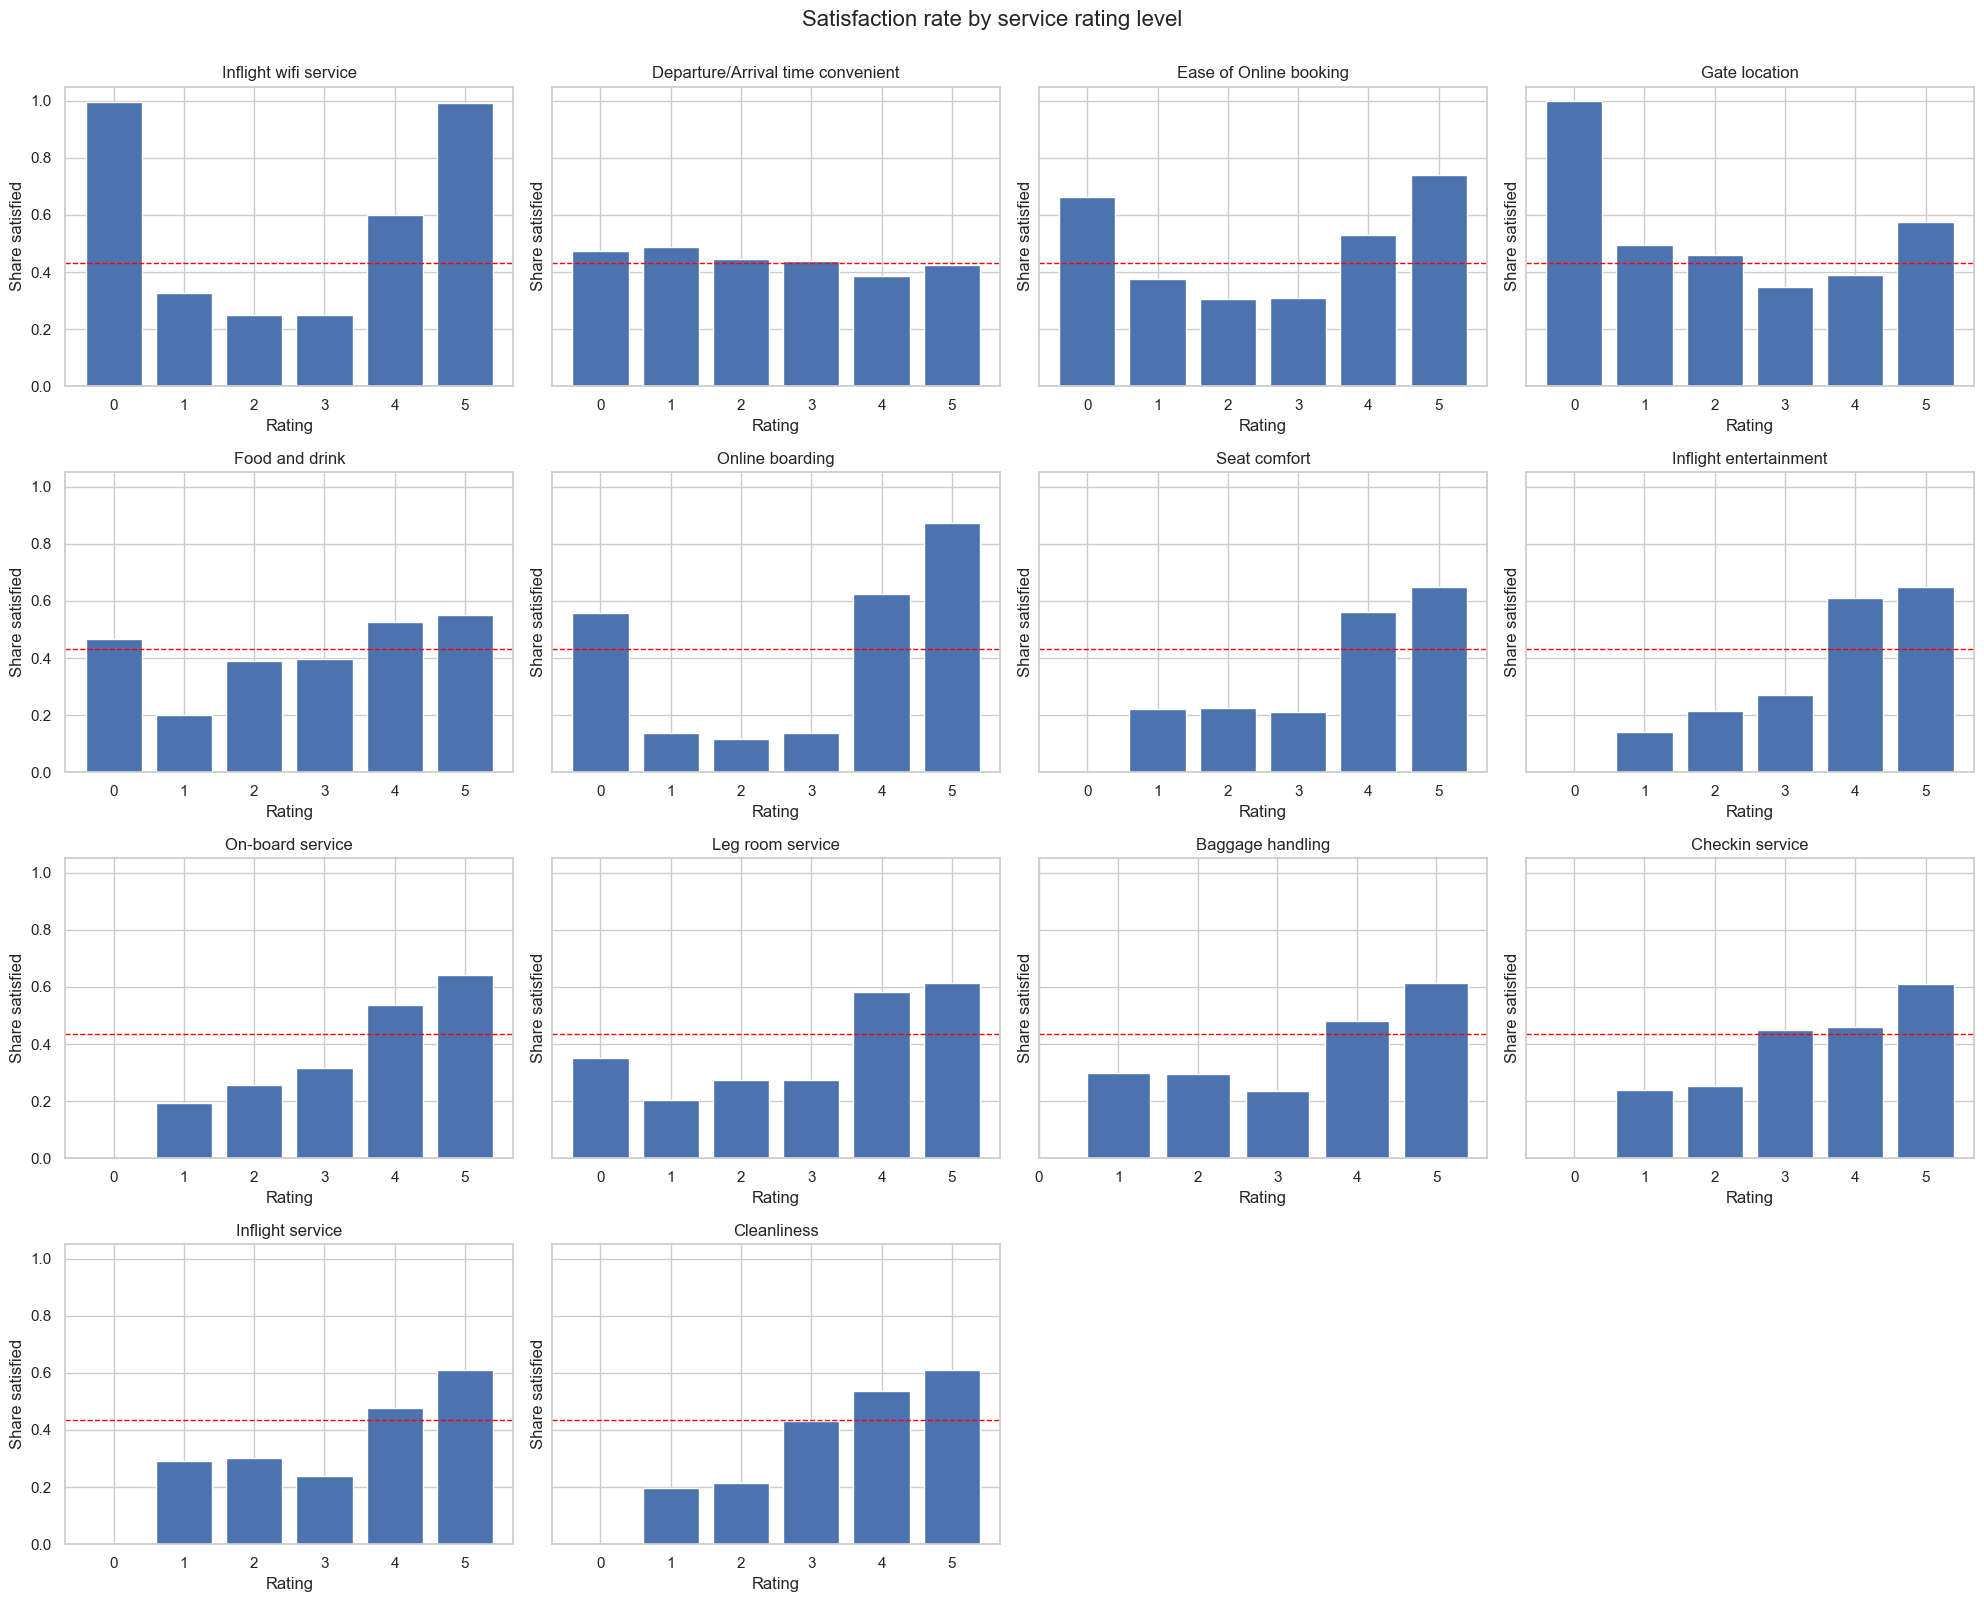

In [9]:
# ---------------------------------------------------------------
# 5. Satisfaction rate at each rating level, for every service
# ---------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(20, 16), sharey=True)
for ax, column in zip(axes.flat, rating_cols):
    level_stats = eda_df.groupby(column)['satisfied'].agg(['mean', 'size'])
    ax.bar(level_stats.index, level_stats['mean'], color='#4c72b0')
    ax.axhline(overall_rate, color='red', linestyle='--', linewidth=1)
    ax.set_title(column)
    ax.set_xlabel('Rating')
    ax.set_ylabel('Share satisfied')
    ax.set_xticks(range(0, 6))
for ax in axes.flat[len(rating_cols):]:
    ax.axis('off')
plt.suptitle('Satisfaction rate by service rating level', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

,Dissatisfied,Satisfied,Gap,Corr with target
Online boarding,2.66,4.03,1.37,0.50
Inflight entertainment,2.89,3.96,1.07,0.40
Seat comfort,3.04,3.97,0.93,0.35
On-board service,3.02,3.86,0.84,0.32
Leg room service,2.99,3.82,0.83,0.31
Cleanliness,2.94,3.74,0.81,0.31
Inflight wifi service,2.40,3.16,0.76,0.28
Checkin service,3.04,3.65,0.60,0.24
Baggage handling,3.38,3.96,0.59,0.25
Inflight service,3.39,3.97,0.58,0.24


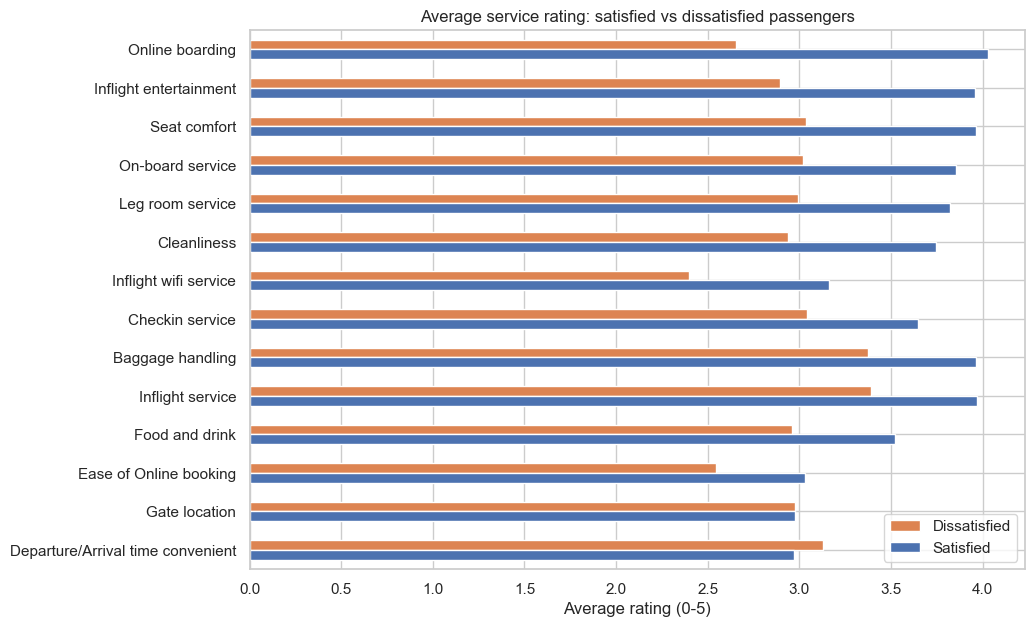

In [10]:
# ---------------------------------------------------------------
# 6. Rank the services: gap in average rating between satisfied
#    and dissatisfied passengers (+ correlation with the target)
# ---------------------------------------------------------------
rating_means = eda_df.groupby('satisfied')[rating_cols].mean().T
rating_means.columns = ['Dissatisfied', 'Satisfied']
rating_means['Gap'] = rating_means['Satisfied'] - rating_means['Dissatisfied']
rating_means['Corr with target'] = eda_df[rating_cols].corrwith(eda_df['satisfied'])
rating_means = rating_means.sort_values('Gap', ascending=False)
display(rating_means.round(2))

rating_means[['Dissatisfied', 'Satisfied']].plot(kind='barh', figsize=(10, 7), color=['#dd8452', '#4c72b0'])
plt.gca().invert_yaxis()
plt.title('Average service rating: satisfied vs dissatisfied passengers')
plt.xlabel('Average rating (0-5)')
plt.show()

### Delays, continuous features and correlations

,share satisfied,passengers
Delay bucket,,
On time,0.458,58668
1-15,0.437,22184
16-30,0.382,8523
31-60,0.364,7290
61-120,0.356,4699
120+,0.361,2540


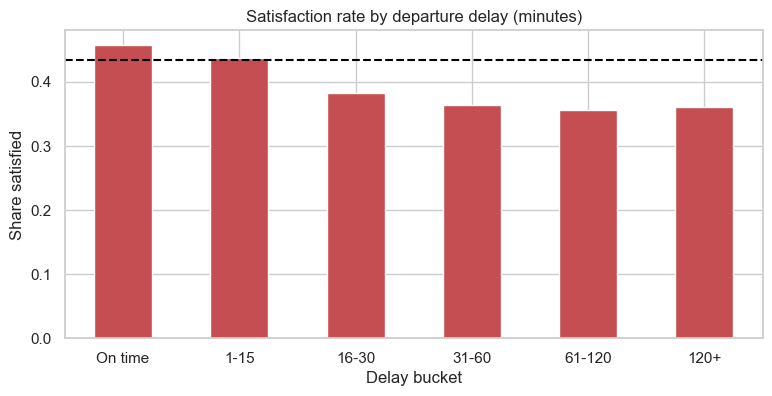

In [11]:
# ---------------------------------------------------------------
# 7. Satisfaction rate by departure-delay bucket
# ---------------------------------------------------------------
eda_df['Delay bucket'] = pd.cut(eda_df['Departure Delay in Minutes'], bins=[-np.inf, 0, 15, 30, 60, 120, np.inf],
                                labels=['On time', '1-15', '16-30', '31-60', '61-120', '120+'])
delay_stats = eda_df.groupby('Delay bucket', observed=True)['satisfied'].agg(['mean', 'size'])
display(delay_stats.rename(columns={'mean': 'share satisfied', 'size': 'passengers'}).round(3))

delay_stats['mean'].plot(kind='bar', figsize=(9, 4), color='#c44e52')
plt.axhline(overall_rate, color='black', linestyle='--')
plt.title('Satisfaction rate by departure delay (minutes)')
plt.ylabel('Share satisfied')
plt.xticks(rotation=0)
plt.show()

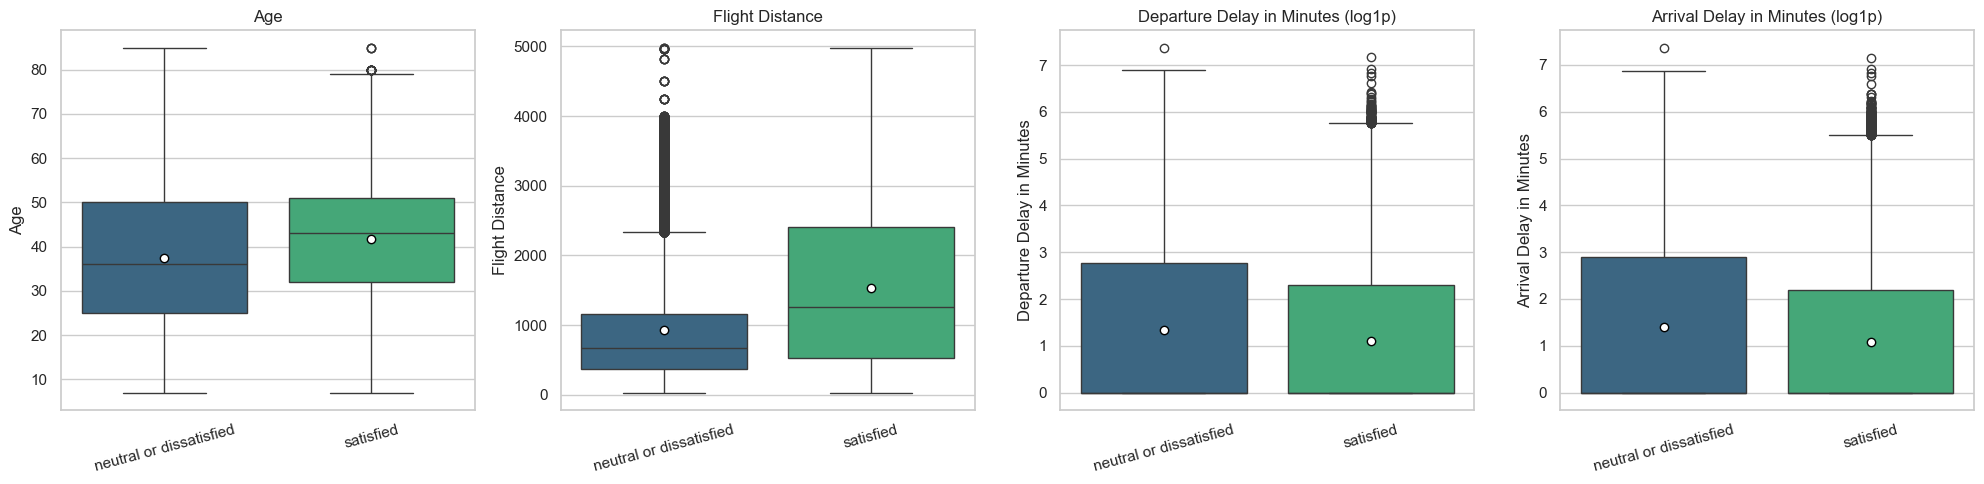

Skewness of continuous features:
Age                          -0.00
Flight Distance               1.11
Departure Delay in Minutes    6.73
Arrival Delay in Minutes      6.60
dtype: float64


In [12]:
# ---------------------------------------------------------------
# 8. Box plots of continuous features by satisfaction
#    (delays use a log y-axis because they are extremely skewed)
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, feature_name in zip(axes, continuous_cols):
    plot_data = eda_df.copy()
    if 'Delay' in feature_name:
        plot_data[feature_name] = np.log1p(plot_data[feature_name])
    sns.boxplot(x='satisfaction label', y=feature_name, data=plot_data, hue='satisfaction label', palette='viridis',
                ax=ax, showmeans=True,
                meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
    ax.set_title(f'{feature_name}' + (' (log1p)' if 'Delay' in feature_name else ''))
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

# Skewness of the continuous features – motivates the log transform used in the pipeline
print('Skewness of continuous features:')
print(eda_df[continuous_cols].skew().round(2))

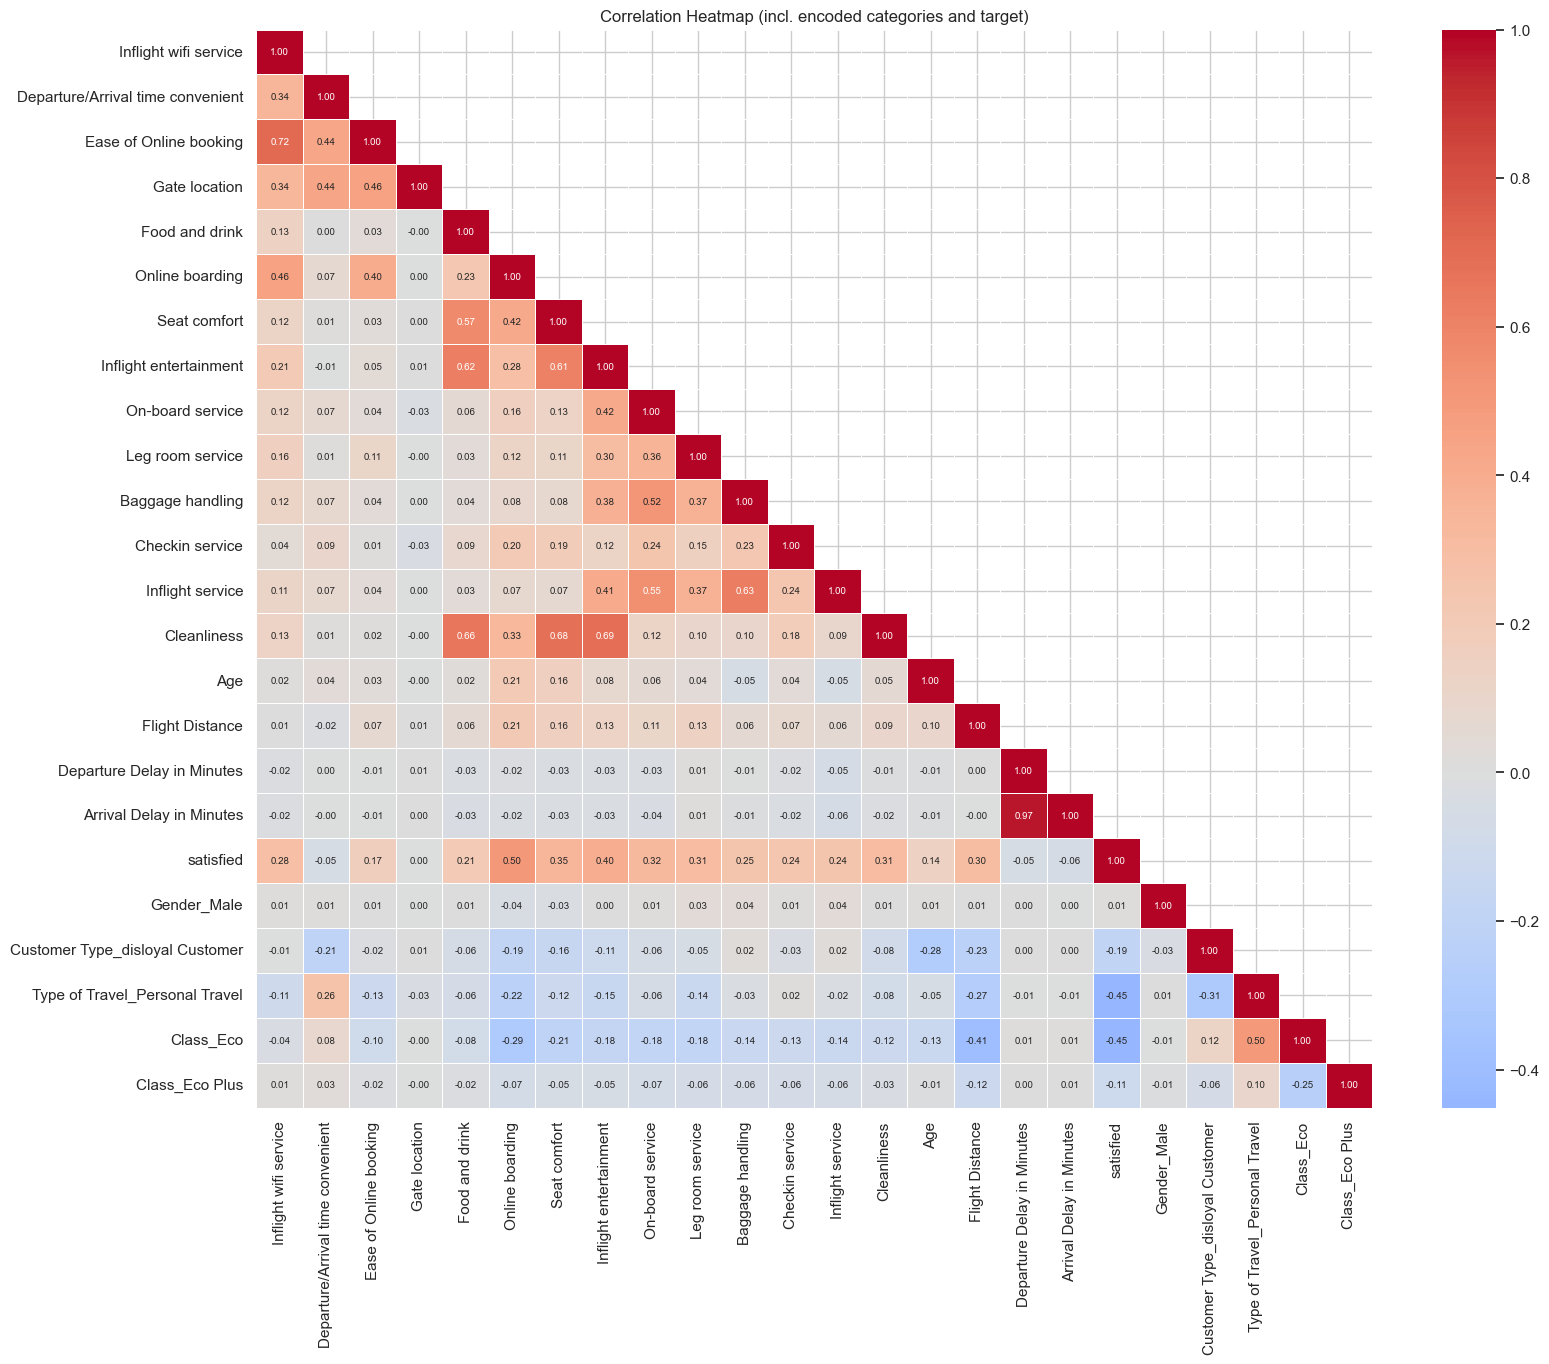

Departure vs Arrival delay correlation: 0.965


In [13]:
# ---------------------------------------------------------------
# 9. Correlation heatmap – numeric features + encoded categories + target
# ---------------------------------------------------------------
corr_df = pd.get_dummies(eda_df[categorical_cols + rating_cols + continuous_cols + ['satisfied']],
                         columns=categorical_cols, drop_first=True, dtype=int)
correlation_matrix = corr_df.corr()

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 7})
plt.title('Correlation Heatmap (incl. encoded categories and target)')
plt.show()

print('Departure vs Arrival delay correlation:',
      round(correlation_matrix.loc['Departure Delay in Minutes', 'Arrival Delay in Minutes'], 3))

**Departure and Arrival delay are almost perfectly correlated (~0.97)**, so they carry the same information. Only *Departure Delay* is kept for modelling – it has fewer missing values and keeps the interpretation clean.

In [14]:
# ---------------------------------------------------------------
# 10. Is missingness itself informative?
#     Compare the satisfaction rate when a value is missing vs present
# ---------------------------------------------------------------
missing_cols = [c for c in eda_df.columns if eda_df[c].isnull().any() and c not in ['Age group', 'Distance band', 'Delay bucket', 'satisfaction label']]
missing_effect = pd.DataFrame({
    'share missing': [eda_df[c].isnull().mean() for c in missing_cols],
    'satisfied when missing': [eda_df.loc[eda_df[c].isnull(), 'satisfied'].mean() for c in missing_cols],
    'satisfied when present': [eda_df.loc[eda_df[c].notnull(), 'satisfied'].mean() for c in missing_cols],
}, index=missing_cols).round(3)
missing_effect

,share missing,satisfied when missing,satisfied when present
Age,0.090,0.439,0.433
Flight Distance,0.100,0.435,0.433
Gate location,0.070,0.436,0.433
Inflight entertainment,0.200,0.436,0.433
Baggage handling,0.085,0.438,0.433
Arrival Delay in Minutes,0.003,0.413,0.433


On the original 104k-row dataset the satisfaction rate is practically the same whether a value is missing or present (~43.5 % vs 43.3 %), so the gaps look **random** (likely injected into the dataset) rather than informative. Simple median / most-frequent imputation is therefore safe. The pipeline still adds a **missing-indicator flag** for each imputed column – it costs nothing and lets the models confirm that missingness carries no signal.

# Data Pre-processing

Every fitted preprocessing step (imputation, scaling) now lives inside a scikit-learn **`Pipeline`**. This guarantees that statistics such as the median are learned **only from training data** – both during cross-validation and in the final test – so nothing leaks from the test set.

| Feature group | Steps |
|---|---|
| Continuous (`Age`, `Flight Distance`, `Departure Delay`) | median imputation + missing flag → `log1p` for the skewed ones → standard scaling |
| Service ratings (0–5) | most-frequent imputation (keeps valid integer ratings) + missing flag → standard scaling |
| Categorical (`Gender`, `Customer Type`, `Type of Travel`, `Class`) | one-hot encoding |

Identifier columns (`Unnamed: 0`, `id`) and the redundant `Arrival Delay in Minutes` are dropped.

In [15]:
# ---------------------------------------------------------------
# Feature matrix / target and a stratified train-test split
# (the split happens BEFORE any imputation, scaling or resampling)
# ---------------------------------------------------------------
model_df = airline_df.drop(columns=ID_COLS + ['Arrival Delay in Minutes'], errors='ignore')
y_target = to_binary(model_df.pop(TARGET_COL))
X_features = model_df

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.2, stratify=y_target, random_state=RANDOM_STATE)

print('Train shape:', X_train.shape, '| Test shape:', X_test.shape)
print('Satisfied share – train: {:.3f}, test: {:.3f}'.format(y_train.mean(), y_test.mean()))

# The competition training data is large (~700k rows). Cross-validation and tuning run on a
# stratified sample to keep the runtime reasonable; the chosen models are refit on the full training split.
TUNING_SAMPLE_SIZE = 100_000
if len(X_train) > TUNING_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNING_SAMPLE_SIZE,
                                            stratify=y_train, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train, y_train
print('Rows used for cross-validation / tuning:', len(X_tune))

Train shape: (83123, 21) | Test shape: (20781, 21)
Satisfied share – train: 0.433, test: 0.433
Rows used for cross-validation / tuning: 83123


In [16]:
# ---------------------------------------------------------------
# Preprocessing pipeline (fitted on training folds only)
# ---------------------------------------------------------------
log_cols = [c for c in ['Flight Distance', 'Departure Delay in Minutes'] if c in X_train.columns]   # strongly right-skewed
plain_cols = [c for c in ['Age'] if c in X_train.columns]

log_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()),
])
plain_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
])
rating_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent', add_indicator=True)),
    ('scale', StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('log', log_pipeline, log_cols),
    ('plain', plain_pipeline, plain_cols),
    ('ratings', rating_pipeline, rating_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), categorical_cols),
], verbose_feature_names_out=False)

# Quick look at the transformed feature names
print(list(preprocessor.fit(X_train).get_feature_names_out()))

['Flight Distance', 'Departure Delay in Minutes', 'missingindicator_Flight Distance', 'Age', 'missingindicator_Age', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'missingindicator_Gate location', 'missingindicator_Inflight entertainment', 'missingindicator_Baggage handling', 'Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel', 'Class_Business', 'Class_Eco', 'Class_Eco Plus']


# Handling Class Imbalance

The classes are only mildly imbalanced (~57 / 43). Instead of SMOTE we use:

- a **stratified** train/test split and stratified CV folds, so every split keeps the same class ratio, and
- **class weights** (`class_weight='balanced'` for Logistic Regression / Random Forest, `scale_pos_weight` for XGBoost), which up-weight the minority class during training without creating synthetic rows.

> If SMOTE were used, it would have to be placed *inside* an `imblearn` pipeline so it only resamples the training folds. Applying it before the split – as in the original notebook – puts synthetic copies of training rows into the test set and inflates the scores.

# Model Implementation

Three classifiers are wrapped in the same preprocessing pipeline and compared with **5-fold stratified cross-validation** on the training set (a 100k-row stratified sample when the data is larger), using accuracy, F1 and ROC-AUC (mean ± std). The test set is not touched here.

In [17]:
# ---------------------------------------------------------------
# Baseline models (default hyperparameters + class weights)
# ---------------------------------------------------------------
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'f1', 'roc_auc']

def make_pipeline(model):
    return Pipeline([('prep', preprocessor), ('model', model)])

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'XGBoost': xgb.XGBClassifier(scale_pos_weight=pos_weight, eval_metric='logloss',
                                 random_state=RANDOM_STATE, n_jobs=-1),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
}

baseline_rows = []
for model_label, model in baseline_models.items():
    cv_scores = cross_validate(make_pipeline(model), X_tune, y_tune, cv=cv_strategy, scoring=scoring, n_jobs=1)
    row = {'Model': model_label}
    for metric in scoring:
        row[metric] = f"{cv_scores['test_' + metric].mean():.4f} ± {cv_scores['test_' + metric].std():.4f}"
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows).set_index('Model')
baseline_results

,accuracy,f1,roc_auc
Model,,,
Logistic Regression,0.8692 ± 0.0029,0.8503 ± 0.0033,0.9268 ± 0.0029
XGBoost,0.9595 ± 0.0020,0.9529 ± 0.0024,0.9943 ± 0.0005
Random Forest,0.9597 ± 0.0022,0.9527 ± 0.0027,0.9928 ± 0.0006


# Hyperparameter Tuning

Each model is tuned with **`RandomizedSearchCV`** using the **same 5-fold stratified CV** and **ROC-AUC** as the selection metric. The search spaces are wider than before – in particular XGBoost can now use deeper trees and more estimators than its defaults, which is why the previous (narrower) search ended up *worse* than the untuned model.

In [18]:
# ---------------------------------------------------------------
# Hyperparameter search spaces (parameters are prefixed with the pipeline step name)
# ---------------------------------------------------------------
param_spaces = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 0.3, 1, 3, 10],
        'model__penalty': ['l1', 'l2'],
        'model__solver': ['liblinear'],
    },
    'XGBoost': {
        'model__n_estimators': [200, 400, 600],
        'model__max_depth': [4, 6, 8, 10],
        'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
        'model__subsample': [0.7, 0.85, 1.0],
        'model__colsample_bytree': [0.6, 0.8, 1.0],
        'model__min_child_weight': [1, 3, 5],
        'model__gamma': [0, 0.1, 0.5],
    },
    'Random Forest': {
        'model__n_estimators': [200, 300],
        'model__max_depth': [None, 20, 30],
        'model__max_features': ['sqrt', 0.5],
        'model__min_samples_leaf': [1, 2, 4],
        'model__criterion': ['gini', 'entropy'],
    },
}
n_iter_per_model = {'Logistic Regression': 12, 'XGBoost': 20, 'Random Forest': 8}

In [19]:
# ---------------------------------------------------------------
# Run the searches
# ---------------------------------------------------------------
tuned_models, search_rows = {}, []
for model_label, base_model in baseline_models.items():
    search = RandomizedSearchCV(make_pipeline(base_model), param_distributions=param_spaces[model_label],
                                n_iter=n_iter_per_model[model_label], cv=cv_strategy, scoring='roc_auc',
                                random_state=RANDOM_STATE, n_jobs=1 if model_label != 'Logistic Regression' else -1)
    search.fit(X_tune, y_tune)
    # Refit on the full training split when tuning used a sample
    tuned_models[model_label] = (search.best_estimator_ if len(X_tune) == len(X_train)
                                 else clone(search.best_estimator_).fit(X_train, y_train))
    best_params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    search_rows.append({'Model': model_label, 'Best CV ROC-AUC': round(search.best_score_, 4),
                        'Best parameters': best_params})
    print(f"{model_label}: best CV ROC-AUC = {search.best_score_:.4f}\n  {best_params}")

search_results = pd.DataFrame(search_rows).set_index('Model')

Logistic Regression: best CV ROC-AUC = 0.9269
  {'solver': 'liblinear', 'penalty': 'l1', 'C': 0.01}


XGBoost: best CV ROC-AUC = 0.9946
  {'subsample': 0.85, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 10, 'learning_rate': 0.1, 'gamma': 0.5, 'colsample_bytree': 1.0}


Random Forest: best CV ROC-AUC = 0.9939
  {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'gini'}


# Final Evaluation on the Untouched Test Set

The tuned models are now evaluated **once** on the 20 % hold-out set, which contains only real passengers and was never used for fitting, imputation or model selection.

In [20]:
# ---------------------------------------------------------------
# Comparison table on the test set
# ---------------------------------------------------------------
test_rows = []
for model_label, fitted_model in tuned_models.items():
    test_preds = fitted_model.predict(X_test)
    test_proba = fitted_model.predict_proba(X_test)[:, 1]
    test_rows.append({'Model': model_label,
                      'Accuracy': accuracy_score(y_test, test_preds),
                      'F1': f1_score(y_test, test_preds),
                      'ROC-AUC': roc_auc_score(y_test, test_proba)})
test_results = pd.DataFrame(test_rows).set_index('Model').round(4)
best_model_label = test_results['ROC-AUC'].idxmax()
print('Best model on the test set:', best_model_label)
test_results

Best model on the test set: XGBoost


,Accuracy,F1,ROC-AUC
Model,,,
Logistic Regression,0.8696,0.8516,0.9285
XGBoost,0.9627,0.9567,0.9952
Random Forest,0.9624,0.9561,0.9944



Logistic Regression Classification Report:


                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.89      0.87      0.88     11776
           Satisfied       0.84      0.86      0.85      9005

            accuracy                           0.87     20781
           macro avg       0.87      0.87      0.87     20781
        weighted avg       0.87      0.87      0.87     20781




XGBoost Classification Report:
                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.96      0.97      0.97     11776
           Satisfied       0.96      0.95      0.96      9005

            accuracy                           0.96     20781
           macro avg       0.96      0.96      0.96     20781
        weighted avg       0.96      0.96      0.96     20781




Random Forest Classification Report:
                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.96      0.98      0.97     11776
           Satisfied       0.97      0.94      0.96      9005

            accuracy                           0.96     20781
           macro avg       0.96      0.96      0.96     20781
        weighted avg       0.96      0.96      0.96     20781



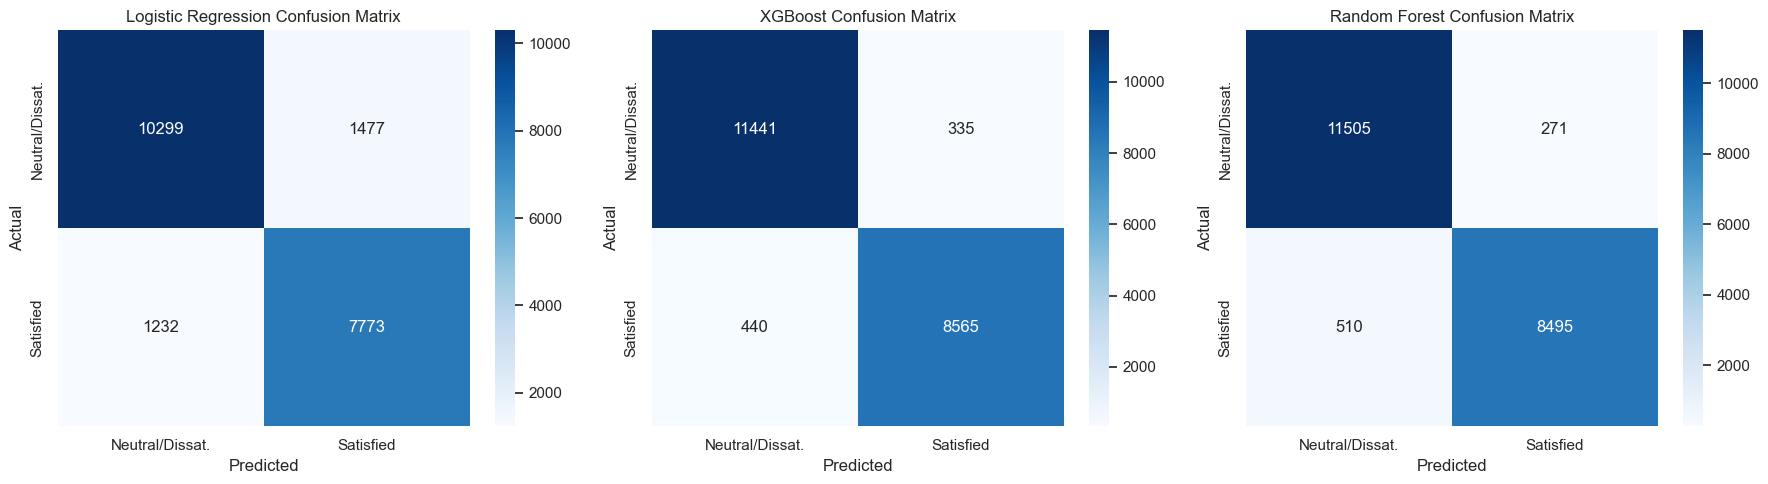

In [21]:
# ---------------------------------------------------------------
# Classification reports + confusion matrices
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model_label, fitted_model) in zip(axes, tuned_models.items()):
    test_preds = fitted_model.predict(X_test)
    print(f"\n{model_label} Classification Report:")
    print(classification_report(y_test, test_preds, target_names=['Neutral/Dissatisfied', 'Satisfied']))
    sns.heatmap(confusion_matrix(y_test, test_preds), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Neutral/Dissat.', 'Satisfied'], yticklabels=['Neutral/Dissat.', 'Satisfied'])
    ax.set_title(f'{model_label} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

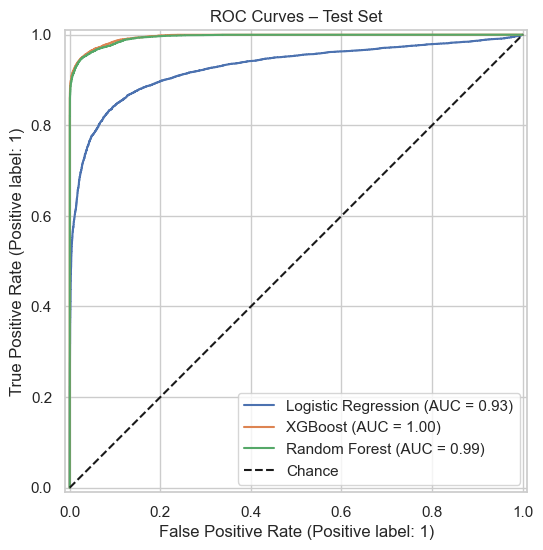

In [22]:
# ---------------------------------------------------------------
# ROC curves for all three models on one plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
for model_label, fitted_model in tuned_models.items():
    RocCurveDisplay.from_estimator(fitted_model, X_test, y_test, name=model_label, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Chance')
ax.set_title('ROC Curves – Test Set')
ax.legend()
plt.show()

# Model Interpretation – What Drives Satisfaction?

Accuracy tells us *how well* we predict; this section explains *why*. Four complementary views are used:

1. **Logistic Regression coefficients** – a simple, linear view of each feature's direction and strength (features are standardised, so coefficients are comparable).
2. **Permutation importance** – how much test-set ROC-AUC drops when a feature is shuffled; model-agnostic and computed on the original columns.
3. **SHAP values** for XGBoost – how much each feature pushes an individual prediction towards *satisfied* or *dissatisfied*.
4. **Partial dependence** – how the predicted probability of satisfaction changes as one feature changes.

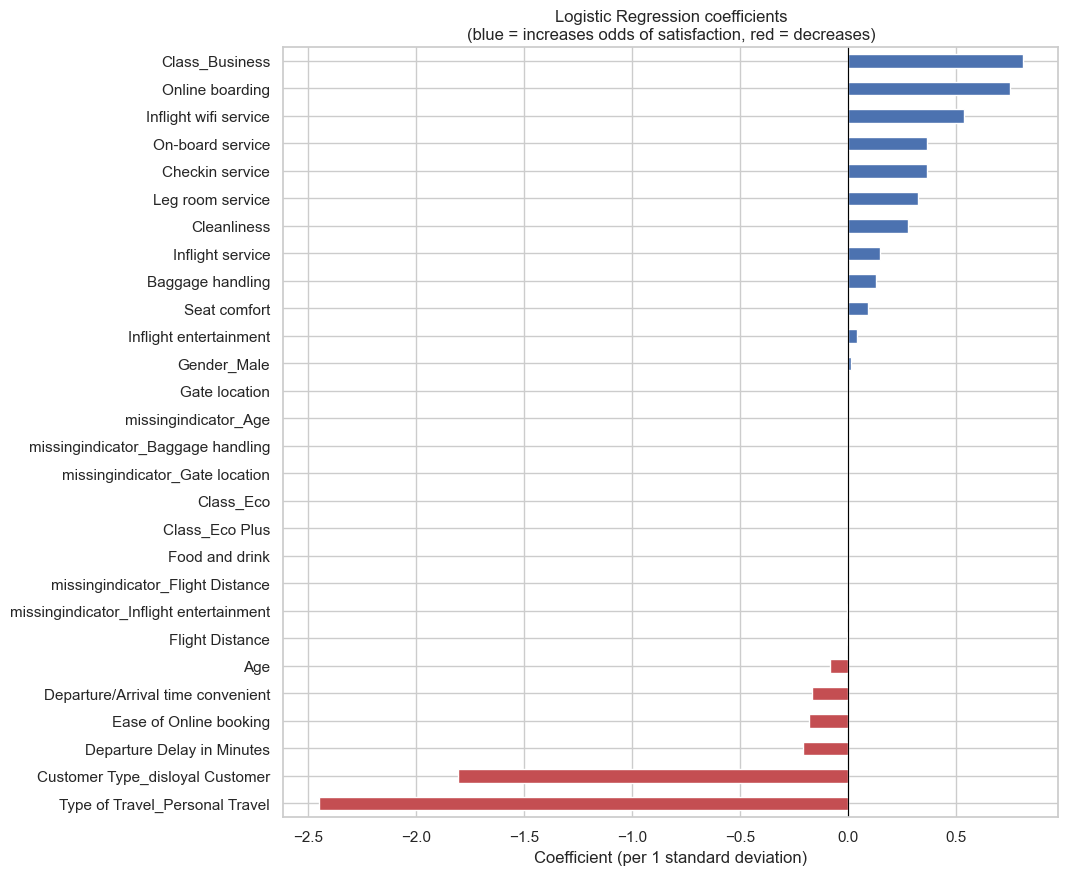

In [23]:
# ---------------------------------------------------------------
# 1. Logistic Regression coefficients (standardised features)
# ---------------------------------------------------------------
lr_pipeline = tuned_models['Logistic Regression']
lr_feature_names = lr_pipeline.named_steps['prep'].get_feature_names_out()
lr_coefs = pd.Series(lr_pipeline.named_steps['model'].coef_[0], index=lr_feature_names).sort_values()

plt.figure(figsize=(10, 10))
lr_coefs.plot(kind='barh', color=np.where(lr_coefs > 0, '#4c72b0', '#c44e52'))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression coefficients\n(blue = increases odds of satisfaction, red = decreases)')
plt.xlabel('Coefficient (per 1 standard deviation)')
plt.show()

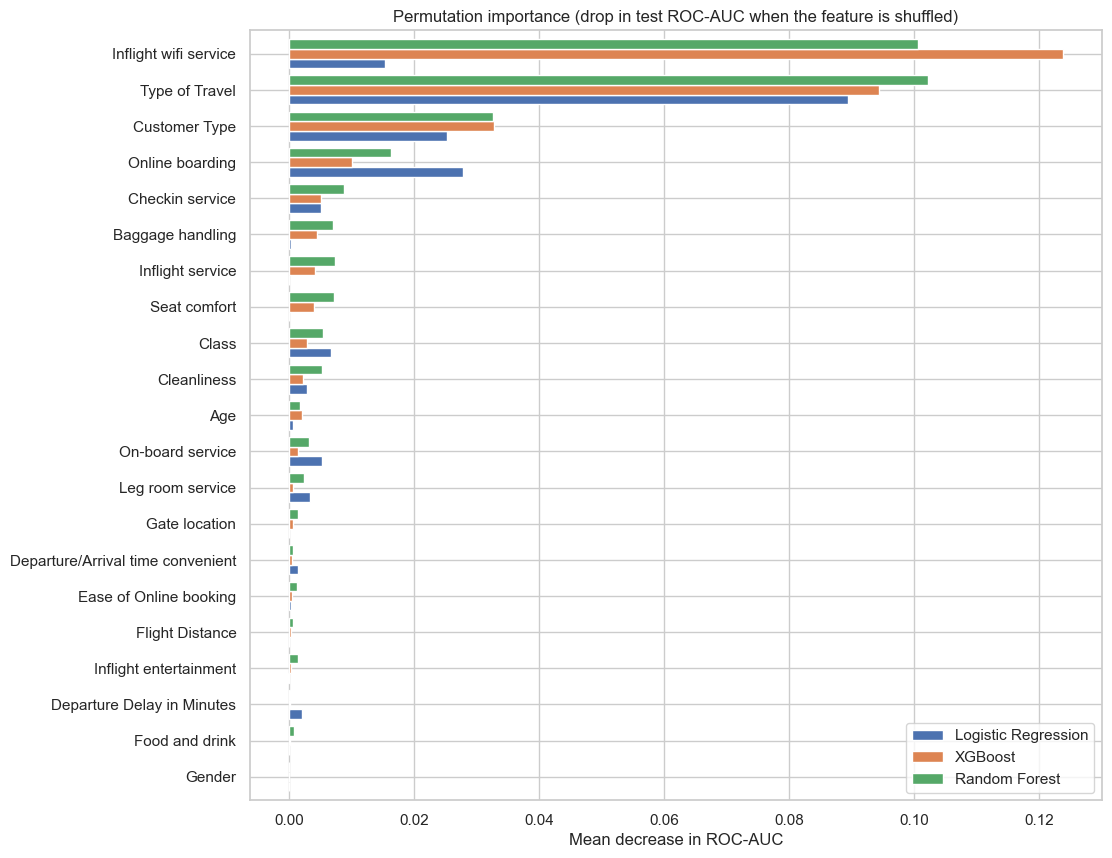

In [24]:
# ---------------------------------------------------------------
# 2. Permutation importance on the test set (all three models)
# ---------------------------------------------------------------
perm_sample = X_test.sample(5000, random_state=RANDOM_STATE)
perm_y = y_test.loc[perm_sample.index]

perm_importances = {}
for model_label, fitted_model in tuned_models.items():
    result = permutation_importance(fitted_model, perm_sample, perm_y, scoring='roc_auc',
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[model_label] = pd.Series(result.importances_mean, index=perm_sample.columns)

perm_df = pd.DataFrame(perm_importances).sort_values(best_model_label, ascending=True)
perm_df.plot(kind='barh', figsize=(11, 10), width=0.8)
plt.title('Permutation importance (drop in test ROC-AUC when the feature is shuffled)')
plt.xlabel('Mean decrease in ROC-AUC')
plt.show()

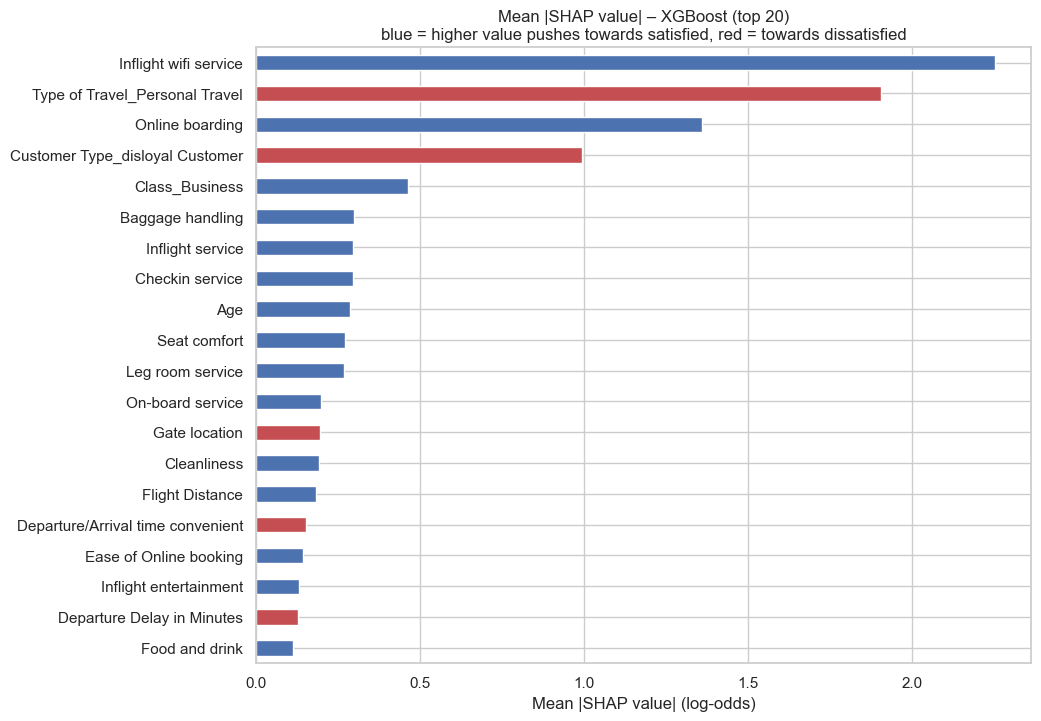

In [25]:
# ---------------------------------------------------------------
# 3. SHAP values for the tuned XGBoost model
#    Uses the `shap` package when installed (preinstalled on Colab);
#    otherwise falls back to XGBoost's built-in SHAP contributions.
# ---------------------------------------------------------------
xgb_pipeline = tuned_models['XGBoost']
shap_sample = X_test.sample(3000, random_state=RANDOM_STATE)
shap_X = pd.DataFrame(xgb_pipeline.named_steps['prep'].transform(shap_sample),
                      columns=xgb_pipeline.named_steps['prep'].get_feature_names_out(), index=shap_sample.index)

try:
    import shap
    explainer = shap.TreeExplainer(xgb_pipeline.named_steps['model'])
    shap_values = explainer.shap_values(shap_X)
    shap.summary_plot(shap_values, shap_X, max_display=20, show=False)
    plt.title('SHAP summary – XGBoost')
    plt.show()
except ImportError:
    booster = xgb_pipeline.named_steps['model'].get_booster()
    contribs = booster.predict(xgb.DMatrix(shap_X), pred_contribs=True)[:, :-1]  # last column = bias
    shap_values = pd.DataFrame(contribs, columns=shap_X.columns, index=shap_X.index)

    # Mean |SHAP| = overall importance; sign of correlation with the feature value = direction
    mean_abs = shap_values.abs().mean().sort_values().tail(20)
    direction = pd.Series({c: np.corrcoef(shap_X[c], shap_values[c])[0, 1] if shap_X[c].std() > 0 else 0
                           for c in mean_abs.index})
    plt.figure(figsize=(10, 8))
    mean_abs.plot(kind='barh', color=np.where(direction > 0, '#4c72b0', '#c44e52'))
    plt.title('Mean |SHAP value| – XGBoost (top 20)\nblue = higher value pushes towards satisfied, red = towards dissatisfied')
    plt.xlabel('Mean |SHAP value| (log-odds)')
    plt.show()

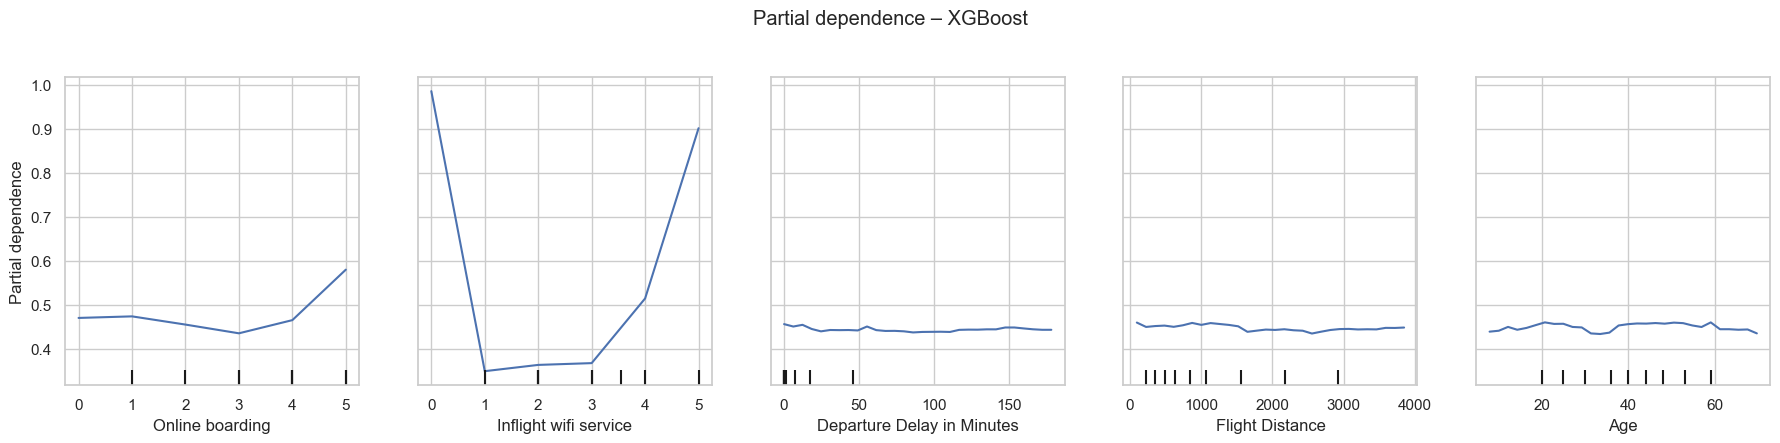

In [26]:
# ---------------------------------------------------------------
# 4. Partial dependence – effect of individual features on the
#    predicted probability of satisfaction (best model)
# ---------------------------------------------------------------
pdp_features = ['Online boarding', 'Inflight wifi service', 'Departure Delay in Minutes', 'Flight Distance', 'Age']
# Rows with missing values in the plotted columns are excluded (NaNs break the PDP grid)
pdp_sample = X_test.dropna(subset=pdp_features).sample(2000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(22, 4))
PartialDependenceDisplay.from_estimator(tuned_models[best_model_label], pdp_sample, pdp_features,
                                        n_cols=5, ax=ax, grid_resolution=30,
                                        percentiles=(0.01, 0.99))
fig.suptitle(f'Partial dependence – {best_model_label}', y=1.05)
plt.show()

### Segment analysis – Business vs Personal travellers

The EDA showed that satisfaction differs strongly by *Type of Travel*. Here we check whether the best model performs equally well for both groups, and whether the **drivers** of satisfaction differ between them.

,Passengers,Share satisfied,Accuracy,ROC-AUC
Segment,,,,
Business travel,14325,0.586,0.966,0.996
Personal Travel,6456,0.094,0.956,0.976


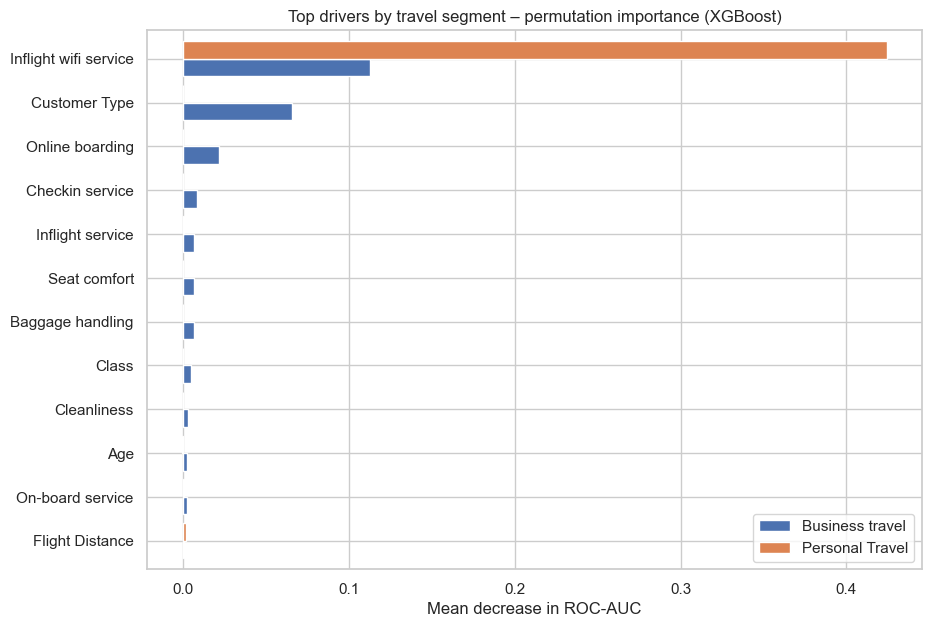

In [27]:
# ---------------------------------------------------------------
# Performance and top drivers per travel segment
# ---------------------------------------------------------------
best_pipeline = tuned_models[best_model_label]
segment_perf, segment_importance = [], {}

for segment in X_test['Type of Travel'].unique():
    seg_mask = X_test['Type of Travel'] == segment
    seg_X, seg_y = X_test[seg_mask], y_test[seg_mask]
    seg_proba = best_pipeline.predict_proba(seg_X)[:, 1]
    segment_perf.append({'Segment': segment, 'Passengers': len(seg_y), 'Share satisfied': seg_y.mean(),
                         'Accuracy': accuracy_score(seg_y, seg_proba > 0.5),
                         'ROC-AUC': roc_auc_score(seg_y, seg_proba)})

    seg_sample = seg_X.sample(min(3000, len(seg_X)), random_state=RANDOM_STATE)
    result = permutation_importance(best_pipeline, seg_sample, seg_y.loc[seg_sample.index], scoring='roc_auc',
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    segment_importance[segment] = pd.Series(result.importances_mean, index=seg_sample.columns)

display(pd.DataFrame(segment_perf).set_index('Segment').round(3))

segment_importance_df = pd.DataFrame(segment_importance).drop(columns=[], errors='ignore')
top_features = segment_importance_df.max(axis=1).sort_values(ascending=False).head(12).index
segment_importance_df.loc[top_features].iloc[::-1].plot(kind='barh', figsize=(10, 7), width=0.8)
plt.title(f'Top drivers by travel segment – permutation importance ({best_model_label})')
plt.xlabel('Mean decrease in ROC-AUC')
plt.show()

In [28]:
# ---------------------------------------------------------------
# Final summary tables
# ---------------------------------------------------------------
print('Cross-validated baseline (train set, 5 folds):')
display(baseline_results)
print('Tuning results:')
display(search_results)
print('Tuned models on the untouched test set:')
display(test_results)

Cross-validated baseline (train set, 5 folds):


,accuracy,f1,roc_auc
Model,,,
Logistic Regression,0.8692 ± 0.0029,0.8503 ± 0.0033,0.9268 ± 0.0029
XGBoost,0.9595 ± 0.0020,0.9529 ± 0.0024,0.9943 ± 0.0005
Random Forest,0.9597 ± 0.0022,0.9527 ± 0.0027,0.9928 ± 0.0006


Tuning results:


,Best CV ROC-AUC,Best parameters
Model,,
Logistic Regression,0.9269,"{'solver': 'liblinear', 'penalty': 'l1', 'C': ..."
XGBoost,0.9946,"{'subsample': 0.85, 'n_estimators': 200, 'min_..."
Random Forest,0.9939,"{'n_estimators': 200, 'min_samples_leaf': 1, '..."


Tuned models on the untouched test set:


,Accuracy,F1,ROC-AUC
Model,,,
Logistic Regression,0.8696,0.8516,0.9285
XGBoost,0.9627,0.9567,0.9952
Random Forest,0.9624,0.9561,0.9944


# Kaggle Submission

The competition is scored on **ROC-AUC**, so the submission contains the **predicted probability** that a passenger is satisfied (not hard 0/1 labels). The best model from the hold-out evaluation is refit on **all labelled rows** (train + hold-out) before predicting `test.csv`, and rows are written in the same order as `sample_submission.csv`.

In [29]:
# ---------------------------------------------------------------
# Refit the best model on all labelled data and write submission.csv
# ---------------------------------------------------------------
if COMPETITION_MODE:
    final_model = clone(tuned_models[best_model_label]).fit(X_features, y_target)

    competition_proba = final_model.predict_proba(competition_test_df[X_features.columns])[:, 1]
    predictions = pd.DataFrame({ID_COL: competition_test_df[ID_COL], TARGET_COL: competition_proba})
    submission = sample_submission[[ID_COL]].merge(predictions, on=ID_COL, how='left')
    assert submission[TARGET_COL].notnull().all(), 'Some test ids have no prediction'

    submission.to_csv('submission.csv', index=False)
    print(f'submission.csv written using {best_model_label}: {submission.shape[0]} rows')
    display(submission.head())
else:
    print('Local mode – no competition test set found, so no submission file was written.')

Local mode – no competition test set found, so no submission file was written.


# Conclusions

_The figures quoted below come from the run on the original 104k-row dataset. The competition data is synthetic, so check them against the outputs above._

**1. Methodology – the scores are now trustworthy**
- The train/test split happens before any fitting, preprocessing lives inside a `Pipeline`, and SMOTE has been replaced by stratification + class weights. The test set contains only real, unseen passengers.
- **XGBoost is the best model**: ~**96.3 % accuracy, F1 0.957, ROC-AUC 0.995** on the untouched test set, with Random Forest a very close second. Cross-validation spread is tiny (± 0.002), so the result is stable.
- Tuning now *improves* the models instead of hurting them (XGBoost CV ROC-AUC 0.9943 → 0.9946). Scaling lifted Logistic Regression from 0.864 to ~0.870 accuracy; its remaining gap shows that the relationships are **non-linear** (see the rating plots).

**2. Who is satisfied – passenger segments**
- **Type of Travel is the biggest split**: 58 % of business travellers are satisfied vs only **10 %** of personal travellers.
- **Class**: Business 69 % vs Eco Plus 25 % vs Eco 19 %. Even inside business travel, Eco passengers are far less satisfied (30 %) than Business class (72 %).
- **Loyalty**: loyal customers 48 % vs disloyal customers 24 %.
- **Age**: satisfaction peaks for 35–54 year-olds (~50–58 %) and is lowest for under-18s and over-65s (~16–18 %). However, the flat partial-dependence curve shows that age has little effect *on its own* – these differences are mostly explained by travel type and class.
- **Gender** has no meaningful effect (43 % vs 44 %).

**3. What drives satisfaction – services**
- **Inflight wifi** and **Online boarding** are by far the most important services in every interpretation method (permutation importance, SHAP, LR coefficients, EDA gap).
- Ratings behave like a **threshold**, not a straight line: ratings 1–3 give similarly low satisfaction, and it jumps sharply at **4–5** (e.g. Online boarding: ~13 % at 1–3 → 87 % at 5). Getting a service from "average" to "good" matters most.
- A wifi rating of **0** ("not applicable") is linked to ~99 % satisfaction – a data quirk that tree models exploit and the partial-dependence plot shows clearly.
- **Gate location, Departure/Arrival time convenience, Food and drink, Flight Distance and Gender** add almost nothing.

**4. Delays**
- Satisfaction drops from 46 % (on time) to ~36 % once the delay exceeds 30 minutes, but the models give delays little weight once service quality is known – service experience outweighs punctuality.

**5. Segment differences**
- For **personal travellers** (only 9 % satisfied) wifi is almost the *only* driver of satisfaction.
- For **business travellers** the drivers are broader: wifi, customer loyalty and online boarding, followed by check-in, in-flight service and seat comfort.

**Recommendations:** prioritise **inflight wifi** and the **online boarding** experience, lift "average" service ratings to "good", and focus retention efforts on **personal / economy travellers** and **disloyal customers**, the groups with the most room for improvement.